<a href="https://colab.research.google.com/github/Fathina-codes/FDS_Record/blob/main/Ex_2_ipynp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

         Date   Product Region  Quantity       Sales  Discount      Profit
0  2024-04-12  Widget A   West        49  845.115681  0.186242  101.919781
1  2024-04-02  Gadget X   East        30  873.525270  0.104224  257.165840
2  2024-01-15  Widget A  South        46  846.556726  0.062739  364.067791
3  2024-04-16  Widget A   East         5  454.786901  0.173895  133.316667
4  2024-03-12  Widget B  South        12  261.447597  0.102469  239.439604
Date        0
Product     3
Region      0
Quantity    0
Sales       5
Discount    0
Profit      0
dtype: int64
         Quantity       Sales    Discount      Profit
count  147.000000  147.000000  147.000000  147.000000
mean    25.673469  524.565576    0.151695  205.588682
std     13.452180  266.056368    0.085984  103.094440
min      1.000000   62.988367    0.000779   14.759198
25%     13.000000  299.796699    0.084749  123.484988
50%     26.000000  523.256927    0.159380  210.917736
75%     36.000000  759.550230    0.222507  292.112001
max    

/tmp/ipykernel_1039/3097794144.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Sales'].fillna(df['Sales'].mean(), inplace=True)


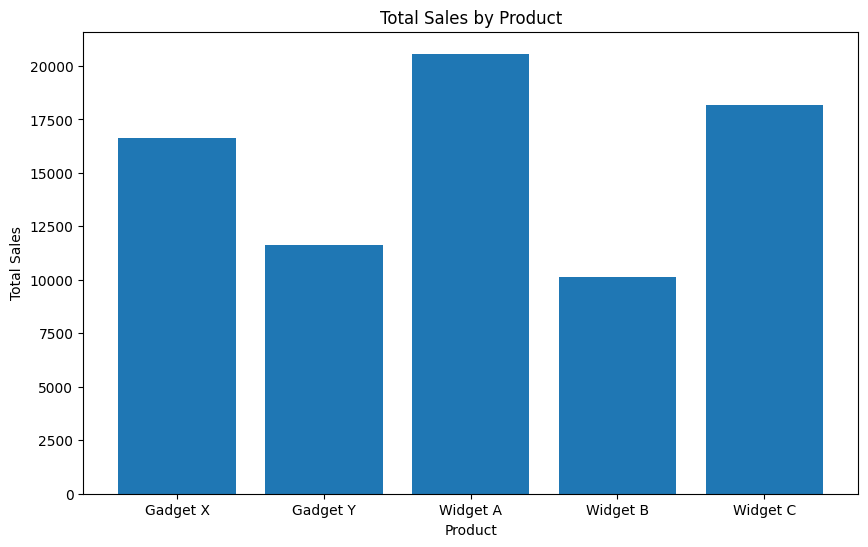

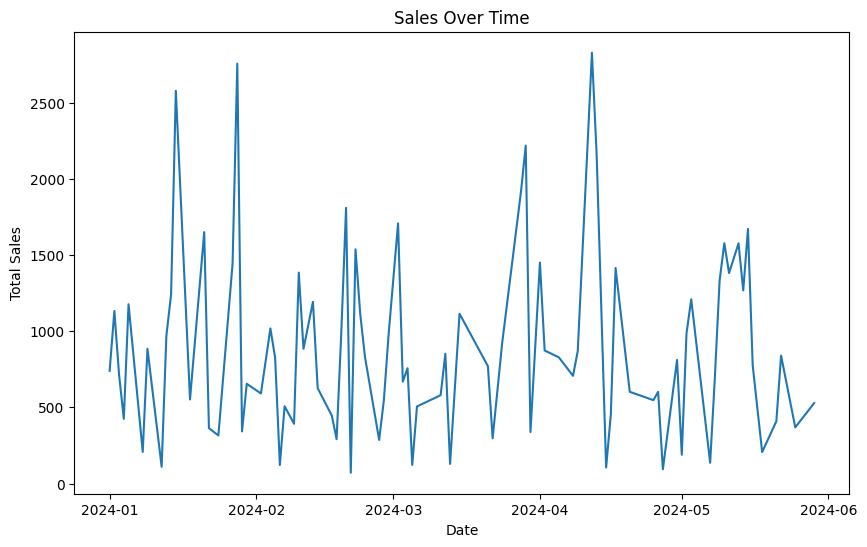

/tmp/ipykernel_1039/3097794144.py:39: FutureWarning: The provided callable <function sum at 0x7ebf10814ea0> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  pivot_table = df.pivot_table(


Product     Gadget X     Gadget Y     Widget A     Widget B     Widget C
Region                                                                  
East     7767.787789  2105.771547  4771.779267   754.260475  3346.681259
North    2322.945525  4277.344971  4677.224103  2986.847290  3294.612428
South    4161.785626   547.710027  5392.354627  3533.301189  6302.819213
West     2355.475385  4691.894150  5728.792694  2853.254510  5238.497632
          Quantity     Sales  Discount    Profit
Quantity  1.000000  0.112707 -0.041174  0.059784
Sales     0.112707  1.000000 -0.071064  0.097612
Discount -0.041174 -0.071064  1.000000  0.036086
Profit    0.059784  0.097612  0.036086  1.000000


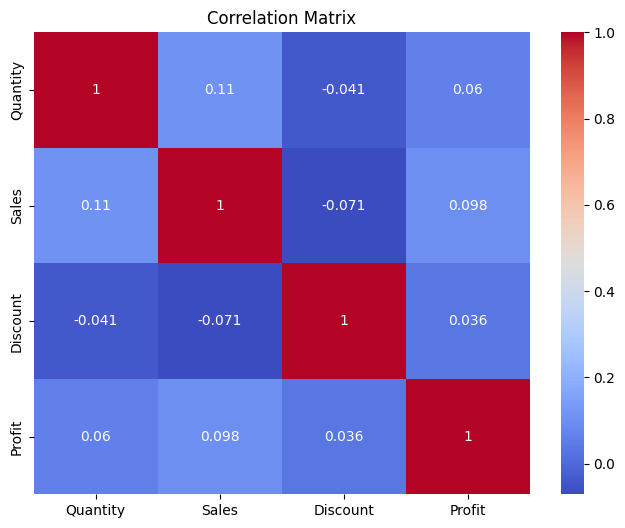

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/sales_data.csv')

print(df.head())
print(df.isnull().sum())

df['Sales'].fillna(df['Sales'].mean(), inplace=True)
df.dropna(subset=['Product', 'Quantity', 'Region'], inplace=True)

print(df.describe())

product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()
print(product_summary)

plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.show()

df['Date'] = pd.to_datetime(df['Date'])
sales_over_time = df.groupby('Date').agg({'Sales': 'sum'}).reset_index()

plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'])
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.show()

pivot_table = df.pivot_table(
    values='Sales',
    index='Region',
    columns='Product',
    aggfunc=np.sum,
    fill_value=0
)
print(pivot_table)

correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()